# Demonstrate a working controller

## 1. Set up the notebook

Do imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, IFrame, HTML
from ae483.tools import *
from ae483.mytools import *
from ae483.design import *

Define name of file with flight data.

In [2]:
filename = 'demonstration_data_smooth3.json'

## 2. Check mocap coverage

Check coverage of mocap data.

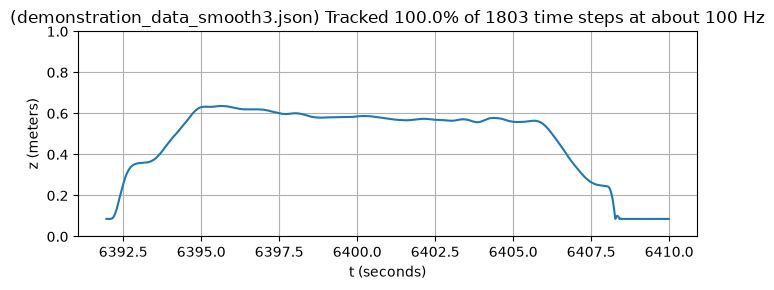

In [3]:
check_mocap_coverage(filename)

## 3. Show results

Load flight data.

In [4]:
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data(filename)

Resample and parse drone data.

In [5]:
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=3, # <-- FIXME
    t_max_offset=0, # <-- FIXME
)

# time
t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

Resample and parse mocap data (with an optimal time shift and with coordinate transformation).

In [6]:
data_mocap = sync_data_mocap(
    raw_data_mocap,
    t,
    p_z,
    do_transform= True,      # <-- whether to align mocap data in space
    t_min_offset=0.,        # <-- how many seconds of mocap data to delete at the start
    t_shift_rng=1,         # <-- range of time shifts over which to search
    t_shift_res=0.05,       # <-- resolution at which to sample time shifts in the range
)

p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

Plot $x, y$ data.

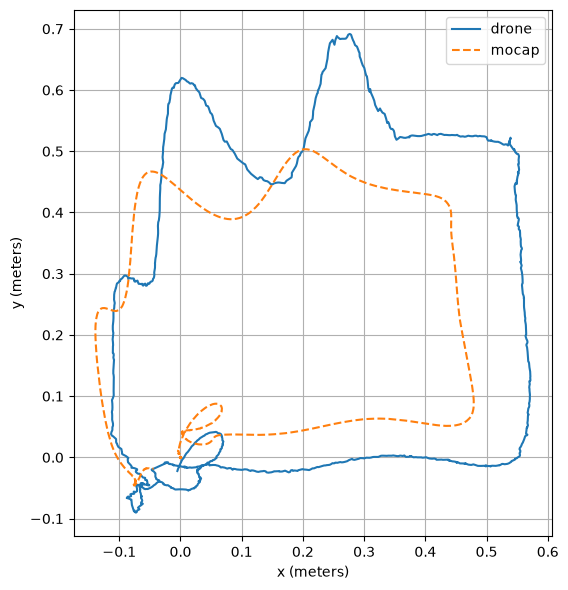

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), tight_layout=True)
ax.plot(p_x, p_y, label='drone')
ax.plot(p_x_mocap, p_y_mocap, '--', label='mocap')
ax.set_aspect('equal')
ax.set_xlabel('x (meters)')
ax.set_ylabel('y (meters)')
ax.legend()
ax.grid()

Plot all data.

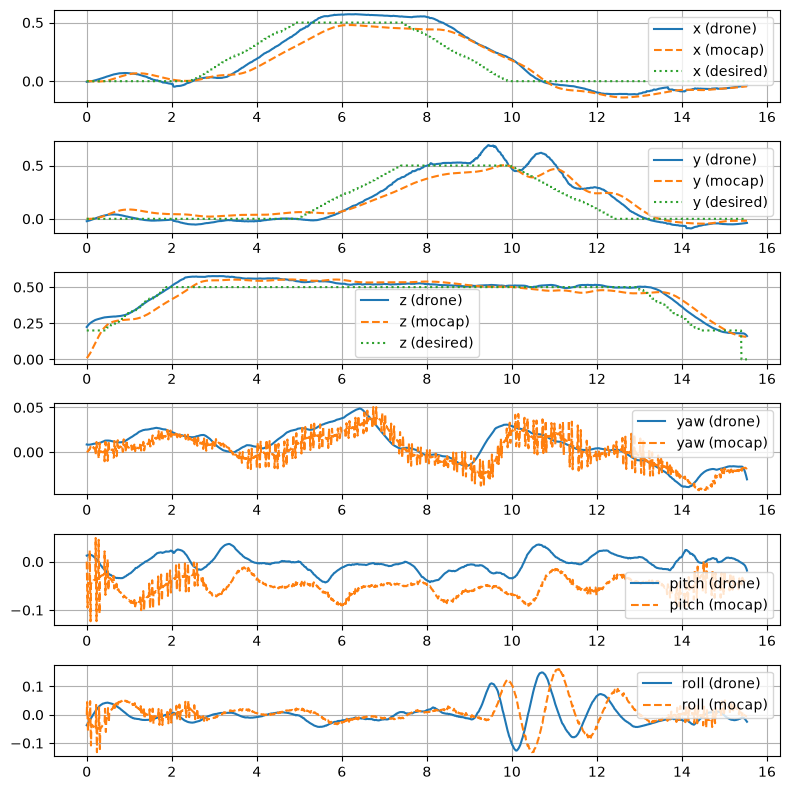

In [8]:
fig, (ax_x, ax_y, ax_z, ax_psi, ax_theta, ax_phi) = plt.subplots(6, 1, figsize=(8, 8), tight_layout=True)

ax_x.plot(t, p_x, label='x (drone)')
ax_x.plot(t, p_x_mocap, '--', label='x (mocap)')
ax_x.plot(t, p_x_des, ':', label='x (desired)')
ax_x.legend()
ax_x.grid()

ax_y.plot(t, p_y, label='y (drone)')
ax_y.plot(t, p_y_mocap, '--', label='y (mocap)')
ax_y.plot(t, p_y_des, ':', label='y (desired)')
ax_y.legend()
ax_y.grid()

ax_z.plot(t, p_z, label='z (drone)')
ax_z.plot(t, p_z_mocap, '--', label='z (mocap)')
ax_z.plot(t, p_z_des, ':', label='z (desired)')
ax_z.legend()
ax_z.grid()

ax_psi.plot(t, psi, label='yaw (drone)')
ax_psi.plot(t, psi_mocap, '--', label='yaw (mocap)')
ax_psi.legend()
ax_psi.grid()

ax_theta.plot(t, theta, label='pitch (drone)')
ax_theta.plot(t, theta_mocap, '--', label='pitch (mocap)')
ax_theta.legend()
ax_theta.grid()

ax_phi.plot(t, phi, label='roll (drone)')
ax_phi.plot(t, phi_mocap, '--', label='roll (mocap)')
ax_phi.legend()
ax_phi.grid()

### Applying only_in_flight and parsing data

In [9]:
only_in_flight(data_drone, data_mocap=data_mocap, t_interval=10.)

t = data_drone['time']

# position
p_x = data_drone['ae483log.p_x']
p_y = data_drone['ae483log.p_y']
p_z = data_drone['ae483log.p_z']

# desired position
p_x_des = data_drone['ae483log.p_x_des']
p_y_des = data_drone['ae483log.p_y_des']
p_z_des = data_drone['ae483log.p_z_des']

# orientation
psi = data_drone['ae483log.psi']
theta = data_drone['ae483log.theta']
phi = data_drone['ae483log.phi']

# motor power commands
m_1 = data_drone['ae483log.m_1']
m_2 = data_drone['ae483log.m_2']
m_3 = data_drone['ae483log.m_3']
m_4 = data_drone['ae483log.m_4']

p_x_mocap = data_mocap['x']
p_y_mocap = data_mocap['y']
p_z_mocap = data_mocap['z']
psi_mocap = data_mocap['yaw']
theta_mocap = data_mocap['pitch']
phi_mocap = data_mocap['roll']

### Replotting x, y data to verify only_in_flight

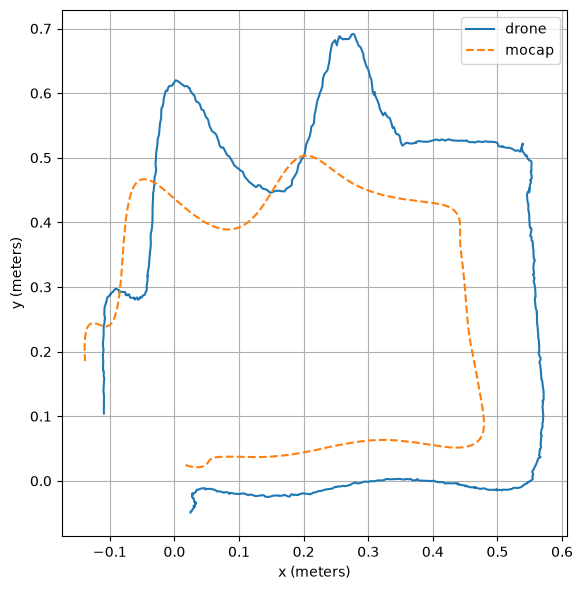

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6), tight_layout=True)
ax.plot(p_x, p_y, label='drone')
ax.plot(p_x_mocap, p_y_mocap, '--', label='mocap')
ax.set_aspect('equal')
ax.set_xlabel('x (meters)')
ax.set_ylabel('y (meters)')
ax.legend()
ax.grid()

### RMSE Computation

In [14]:
p_x_rmse_drone = np.sqrt(np.mean((p_x - p_x_des)**2))
p_y_rmse_drone = np.sqrt(np.mean((p_y - p_y_des)**2))
p_z_rmse_drone = np.sqrt(np.mean((p_z - p_z_des)**2))
psi_rmse_drone = np.sqrt(np.mean((psi - 0.)**2))
theta_rmse_drone = np.sqrt(np.mean((theta - 0.)**2))
phi_rmse_drone = np.sqrt(np.mean((phi - 0.)**2))

p_x_rmse_mocap = np.sqrt(np.mean((p_x - p_x_mocap)**2))
p_y_rmse_mocap = np.sqrt(np.mean((p_y - p_y_mocap)**2))
p_z_rmse_mocap = np.sqrt(np.mean((p_z - p_z_mocap)**2))
psi_rmse_mocap = np.sqrt(np.mean((psi_mocap - 0.)**2))
theta_rmse_mocap = np.sqrt(np.mean((theta_mocap - 0.)**2))
phi_rmse_mocap = np.sqrt(np.mean((phi_mocap - 0.)**2))

print(f'| DRONE DATA | {p_x_rmse_drone:.3f} | {p_y_rmse_drone:.3f} | {p_z_rmse_drone:.3f} | {psi_rmse_drone:.3f} | {theta_rmse_drone:.3f} | {phi_rmse_drone:.3f} |')
print(f'| MOCAP DATA | {p_x_rmse_mocap:.3f} | {p_y_rmse_mocap:.3f} | {p_z_rmse_mocap:.3f} | {psi_rmse_mocap:.3f} | {theta_rmse_mocap:.3f} | {phi_rmse_mocap:.3f} |')


| DRONE DATA | 0.114 | 0.120 | 0.035 | 0.020 | 0.019 | 0.046 |
| MOCAP DATA | 0.070 | 0.088 | 0.021 | 0.017 | 0.056 | 0.048 |


| Data | RMSE in $p_x$ | RMSE in $p_y$ | RMSE in $p_z$ | RMSE in $\psi$ | RMSE in $\theta$ | RMSE in $\phi$ |
| :--: | :--: | :--: | :--: | :--: | :--: | :--: |
| DRONE DATA | 0.114 | 0.120 | 0.035 | 0.020 | 0.019 | 0.046 |
| MOCAP DATA | 0.070 | 0.088 | 0.021 | 0.017 | 0.056 | 0.048 |

Show the gains that were used to produce these results.

In [12]:
show_gains(filename)

Control gains, designed 2026-10-23T12:40:30:
tau_x_cmd:     eq   0.0000    p_y  -0.0286    phi   0.0488    v_y  -0.0175    w_x   0.0072  tau_x   3.3824    e_y  -0.0056
tau_y_cmd:     eq   0.0000    p_x   0.0110  theta   0.0236    v_x   0.0076    w_y   0.0039  tau_y   2.2736    e_x   0.0028
    tau_z:     eq   0.0000    psi   0.0030    w_z   0.0008
      f_z:     eq   0.3335    p_z   0.5062    v_z   0.2316    e_z   0.1386


Show links to a video of your hardware flight test (change the url as appropriate) that was previously uploaded to [Illinois Mediaspace](https://mediaspace.illinois.edu/) and published as **Unlisted**.

In [13]:
# FIXME (REPLACE URL TO SHOW A VIDEO OF YOUR FLIGHT)
mediaspace('https://mediaspace.illinois.edu/media/t/1_e6l539as')

## 4. Reflect

How did RSME values from mocap compare to those from drone data?

**For all RMSE values, the RMSE values between the drone and mocap data were very similar. This makes sense since the data should be aligned. However, slight differences in the position and time transformation of our data causes the RMSE values to not be exactly the same.**

**Modify the text in this cell** to describe, in at least two or three sentences, the biggest struggle you had (with the technical material, with collaboration, etc.) and the most important thing that you learned. Look back at your reflections from the first four labs — have you taken a step forward? Think ahead to next week, when you will be asked to further improve the performance of your controller — what might you do in order to make that process go well?

**This lab took us about three weeks to complete due to the amount of runs we had to adjust the performance of the controller against the default controller. We struggled uderstanding and implmenting the many variables that controlled steady flight performance, including battery voltage. In the end, we achieved a successful controller but at the cost of lots of time. We also struggled in transforming the mocap data due to unforeseen issues in reloading the Lab 2 functions.**